## 1. Carregamento e Preparação Espacial dos Dados

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.1)

from pathlib import Path
# Detecta dinamicamente a pasta de saída e o local da matriz analítica
output_dir = Path('dados_output') if Path('dados_output').exists() or not Path('/content').exists() else Path('/content/dados_output')
output_dir.mkdir(parents=True, exist_ok=True)
output_path = str(output_dir)

# Busca a matriz analítica nos caminhos comuns
candidatos_matriz = [
    output_dir / 'matriz_analitica_kdd_final.parquet',
    Path('matriz_analitica_kdd_final.parquet'),
    Path('/content/matriz_analitica_kdd_final.parquet'),
    Path('/content/dados_output/matriz_analitica_kdd_final.parquet')
]
caminho_matriz_encontrado = next((p for p in candidatos_matriz if p.exists()), output_dir / 'matriz_analitica_kdd_final.parquet')


# 1. Carregamento do Artefato Consolidado
try:
    df_kdd = pd.read_parquet(caminho_matriz_encontrado)
    print(f"[SUCESSO] Matriz carregada. Total de inscrições: {len(df_kdd):,}")
except Exception as e:
    print(f"[ERRO CRÍTICO] Arquivo não encontrado. Erro: {e}")

# 2. Definição do Espaço Vetorial (As variáveis matemáticas que irão para o K-Means)
features_ml = [
    'Idade',
    'Escolaridade_Ordinal',
    'qtd_tentativas',
    'progresso_kdd',
    'nota_final_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p',
    'dias_duracao_curso'
]

features_ml_existentes = [f for f in features_ml if f in df_kdd.columns]
if len(features_ml_existentes) < len(features_ml):
    print(f'[AVISO] Colunas faltando: {set(features_ml) - set(features_ml_existentes)}')
    features_ml = features_ml_existentes


print("\n[PREPARANDO ROTA A - Rede Global (Inclui Evasões)]")
df_rota_a = df_kdd.copy()

scaler_a = StandardScaler()
scaled_features_a = scaler_a.fit_transform(df_rota_a[features_ml])
df_rota_a_scaled = pd.DataFrame(scaled_features_a, columns=features_ml, index=df_rota_a.index)

# Reanexa as colunas demográficas/identificação para análise posterior dos clusters
cols_identificacao = [col for col in df_rota_a.columns if col not in features_ml]
df_ml_a = pd.concat([df_rota_a[cols_identificacao], df_rota_a_scaled], axis=1)

print(f"   -> Rota A instanciada: {len(df_ml_a):,} registros padronizados.")

print("\n[PREPARANDO ROTA B - Engajamento Validado (Exclui Imputações)]")

# Filtro estrito: Apenas quem tem nota e tempo reais (flags zeradas)
mask_ativos = (df_kdd['flg_nota_imputada'] == 0) & (df_kdd['flg_tempo_imputado'] == 0)
df_rota_b = df_kdd[mask_ativos].copy()

scaler_b = StandardScaler()
scaled_features_b = scaler_b.fit_transform(df_rota_b[features_ml])
df_rota_b_scaled = pd.DataFrame(scaled_features_b, columns=features_ml, index=df_rota_b.index)

# Reanexa as colunas demográficas/identificação
df_ml_b = pd.concat([df_rota_b[cols_identificacao], df_rota_b_scaled], axis=1)

print(f"   -> Rota B instanciada: {len(df_ml_b):,} registros de alto engajamento padronizados.")


[SUCESSO] Matriz carregada. Total de inscrições: 191,412

[PREPARANDO ROTA A - Rede Global (Inclui Evasões)]
   -> Rota A instanciada: 191,412 registros padronizados.

[PREPARANDO ROTA B - Engajamento Validado (Exclui Imputações)]
   -> Rota B instanciada: 34,985 registros de alto engajamento padronizados.


## 2. Otimização do Hiperparâmetro $K$ (Validação Interna de Clusters)

Treinando modelo para K=2...
   -> Concluído K=2 | Inércia: 225,593 | Silhueta: 0.3757
Treinando modelo para K=3...
   -> Concluído K=3 | Inércia: 188,719 | Silhueta: 0.2453
Treinando modelo para K=4...
   -> Concluído K=4 | Inércia: 157,041 | Silhueta: 0.2547
Treinando modelo para K=5...
   -> Concluído K=5 | Inércia: 132,015 | Silhueta: 0.2523
Treinando modelo para K=6...
   -> Concluído K=6 | Inércia: 115,025 | Silhueta: 0.2700
Treinando modelo para K=7...
   -> Concluído K=7 | Inércia: 105,083 | Silhueta: 0.2599
Treinando modelo para K=8...
   -> Concluído K=8 | Inércia: 98,552 | Silhueta: 0.2344

VARREDURA CONCLUÍDA EM 2.1 MINUTOS. GERANDO GRÁFICOS HEURÍSTICOS...
----------------------------------------------------------------------


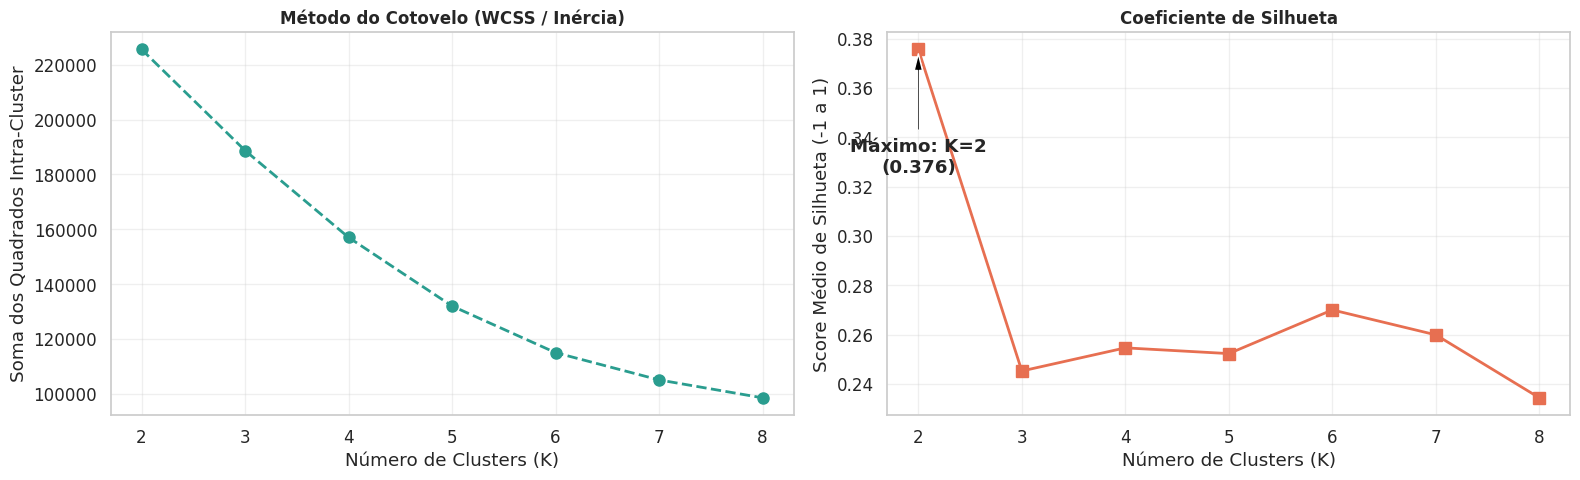

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

inicio_tempo = time.time()

# Isolando apenas as variáveis numéricas estritamente escalonadas
X_b = df_ml_b[features_ml]

# Estruturas para armazenar os resultados matemáticos
inercia = []
silhueta = []
intervalo_k = range(2, 9)

# Loop de treinamento e avaliação geométrica
for k in intervalo_k:
    print(f"Treinando modelo para K={k}...")
    # Instancia o modelo K-Means com seed 42 para reprodutibilidade estrita
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_b)

    # 1. Armazena o WCSS (Inércia / Coesão)
    inercia.append(kmeans.inertia_)

    # 2. Armazena o Coeficiente de Silhueta (Separação)
    score_sil = silhouette_score(X_b, labels)
    silhueta.append(score_sil)

    print(f"   -> Concluído K={k} | Inércia: {kmeans.inertia_:,.0f} | Silhueta: {score_sil:.4f}")

tempo_total = (time.time() - inicio_tempo) / 60
print("\n" + "=" * 70)
print(f"VARREDURA CONCLUÍDA EM {tempo_total:.1f} MINUTOS. GERANDO GRÁFICOS HEURÍSTICOS...")
print("-" * 70)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(intervalo_k, inercia, marker='o', linestyle='--', color='#2a9d8f', linewidth=2, markersize=8)
axes[0].set_title('Método do Cotovelo (WCSS / Inércia)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('Soma dos Quadrados Intra-Cluster')
axes[0].set_xticks(intervalo_k)
axes[0].grid(True, alpha=0.3)

axes[1].plot(intervalo_k, silhueta, marker='s', linestyle='-', color='#e76f51', linewidth=2, markersize=8)
axes[1].set_title('Coeficiente de Silhueta', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Score Médio de Silhueta (-1 a 1)')
axes[1].set_xticks(intervalo_k)
axes[1].grid(True, alpha=0.3)

k_max_sil = intervalo_k[np.argmax(silhueta)]
max_sil_val = max(silhueta)
axes[1].annotate(f'Máximo: K={k_max_sil}\n({max_sil_val:.3f})',
                 xy=(k_max_sil, max_sil_val),
                 xytext=(k_max_sil, max_sil_val - 0.05),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
                 horizontalalignment='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 3 Redução de Dimensionalidade: Análise de Componentes Principais (PCA)

[ANÁLISE DE VARIÂNCIA DOS COMPONENTES]
-> PC1: Explica 24.09% da variância | Cumulativo: 24.09%
-> PC2: Explica 18.29% da variância | Cumulativo: 42.38%
-> PC3: Explica 18.08% da variância | Cumulativo: 60.46%
-> PC4: Explica 11.96% da variância | Cumulativo: 72.41%
-> PC5: Explica 11.37% da variância | Cumulativo: 83.78%
-> PC6: Explica 8.47% da variância | Cumulativo: 92.25%
-> PC7: Explica 5.62% da variância | Cumulativo: 97.87%
-> PC8: Explica 2.13% da variância | Cumulativo: 100.00%


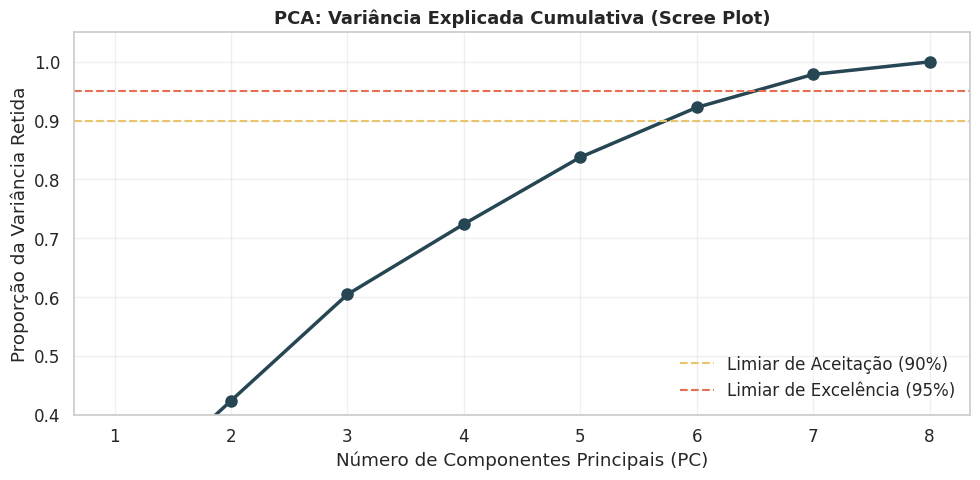


APLICANDO TRANSFORMAÇÃO ORTOGONAL (LIMIAR DE 95%)
----------------------------------------------------------------------
[RESULTADO DA TRANSFORMAÇÃO ESPACIAL]
-> Redução dimensional: De 8 dimensões originais para 7 Componentes Principais.
-> O subespaço vetorial comprimido (X_pca_b) preserva 97.87% da variância comportamental.


In [22]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Instanciando o PCA para mapear 100% da variância original (8 features)
pca_full = PCA(random_state=42)
pca_full.fit(X_b) # X_b corresponde à matriz padronizada do eixo anterior

# Calculando a variância explicada (individual) e cumulativa
variancia_explicada = pca_full.explained_variance_ratio_
variancia_cumulativa = np.cumsum(variancia_explicada)

print("[ANÁLISE DE VARIÂNCIA DOS COMPONENTES]")
for i, (var, cum_var) in enumerate(zip(variancia_explicada, variancia_cumulativa), start=1):
    print(f"-> PC{i}: Explica {var*100:.2f}% da variância | Cumulativo: {cum_var*100:.2f}%")

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(variancia_explicada) + 1), variancia_cumulativa, marker='o',
         linestyle='-', color='#264653', linewidth=2.5, markersize=8)

# Linhas de corte (Limiares Metodológicos)
plt.axhline(y=0.90, color='#e9c46a', linestyle='--', label='Limiar de Aceitação (90%)')
plt.axhline(y=0.95, color='#e76f51', linestyle='--', label='Limiar de Excelência (95%)')

plt.title('PCA: Variância Explicada Cumulativa (Scree Plot)', fontweight='bold', fontsize=13)
plt.xlabel('Número de Componentes Principais (PC)')
plt.ylabel('Proporção da Variância Retida')
plt.xticks(range(1, len(variancia_explicada) + 1))
plt.ylim(0.4, 1.05)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("APLICANDO TRANSFORMAÇÃO ORTOGONAL (LIMIAR DE 95%)")
print("-" * 70)

pca_opt = PCA(n_components=0.95, random_state=42)
X_pca_b = pca_opt.fit_transform(X_b)

n_comp_opt = pca_opt.n_components_
var_final = np.sum(pca_opt.explained_variance_ratio_) * 100

print(f"[RESULTADO DA TRANSFORMAÇÃO ESPACIAL]")
print(f"-> Redução dimensional: De {X_b.shape[1]} dimensões originais para {n_comp_opt} Componentes Principais.")
print(f"-> O subespaço vetorial comprimido (X_pca_b) preserva {var_final:.2f}% da variância comportamental.")

Revalidando as métricas geométricas no subespaço ortogonal (PCA)...
Calculando WCSS e Silhouette para K de 2 a 8 na matriz reduzida.
----------------------------------------------------------------------
Treinando modelo no espaço PCA para K=2...
   -> Concluído K=2 (PCA) | Inércia: 219,636 | Silhueta: 0.3770
Treinando modelo no espaço PCA para K=3...
   -> Concluído K=3 (PCA) | Inércia: 182,761 | Silhueta: 0.2508
Treinando modelo no espaço PCA para K=4...
   -> Concluído K=4 (PCA) | Inércia: 151,079 | Silhueta: 0.2609
Treinando modelo no espaço PCA para K=5...
   -> Concluído K=5 (PCA) | Inércia: 126,051 | Silhueta: 0.2600
Treinando modelo no espaço PCA para K=6...
   -> Concluído K=6 (PCA) | Inércia: 109,070 | Silhueta: 0.2785
Treinando modelo no espaço PCA para K=7...
   -> Concluído K=7 (PCA) | Inércia: 99,129 | Silhueta: 0.2694
Treinando modelo no espaço PCA para K=8...
   -> Concluído K=8 (PCA) | Inércia: 92,601 | Silhueta: 0.2443

REVALIDAÇÃO CONCLUÍDA EM 1.9 MINUTOS. GERANDO GR

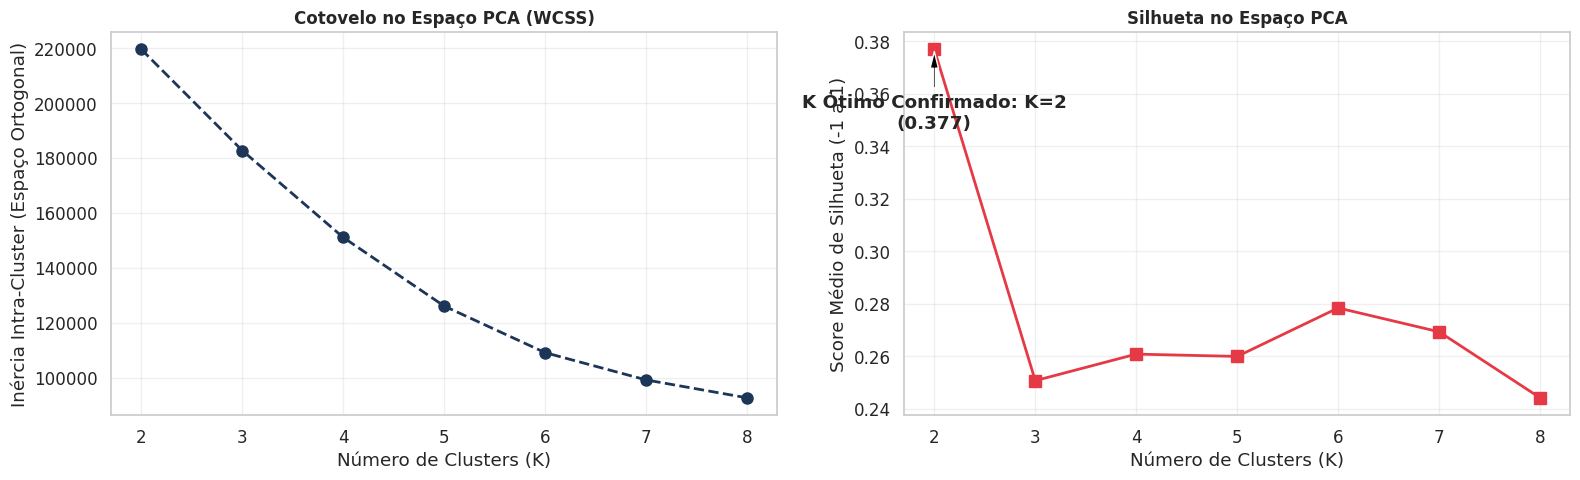

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import time

print("Revalidando as métricas geométricas no subespaço ortogonal (PCA)...")
print("Calculando WCSS e Silhouette para K de 2 a 8 na matriz reduzida.")
print("-" * 70)

inicio_tempo = time.time()

inercia_pca = []
silhueta_pca = []
intervalo_k = range(2, 9)

# Loop de treinamento focado exclusivamente na matriz comprimida X_pca_b
for k in intervalo_k:
    print(f"Treinando modelo no espaço PCA para K={k}...")
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels_pca = kmeans.fit_predict(X_pca_b)

    inercia_pca.append(kmeans.inertia_)
    score_sil_pca = silhouette_score(X_pca_b, labels_pca)
    silhueta_pca.append(score_sil_pca)

    print(f"   -> Concluído K={k} (PCA) | Inércia: {kmeans.inertia_:,.0f} | Silhueta: {score_sil_pca:.4f}")

tempo_total = (time.time() - inicio_tempo) / 60
print("\n" + "=" * 70)
print(f"REVALIDAÇÃO CONCLUÍDA EM {tempo_total:.1f} MINUTOS. GERANDO GRÁFICOS...")
print("-" * 70)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Método do Cotovelo (Inércia no PCA)
axes[0].plot(intervalo_k, inercia_pca, marker='o', linestyle='--', color='#1d3557', linewidth=2, markersize=8)
axes[0].set_title('Cotovelo no Espaço PCA (WCSS)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('Inércia Intra-Cluster (Espaço Ortogonal)')
axes[0].set_xticks(intervalo_k)
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Coeficiente de Silhueta (PCA)
axes[1].plot(intervalo_k, silhueta_pca, marker='s', linestyle='-', color='#e63946', linewidth=2, markersize=8)
axes[1].set_title('Silhueta no Espaço PCA', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Score Médio de Silhueta (-1 a 1)')
axes[1].set_xticks(intervalo_k)
axes[1].grid(True, alpha=0.3)

# Anotação visual acadêmica
k_max_sil_pca = intervalo_k[np.argmax(silhueta_pca)]
max_sil_val_pca = max(silhueta_pca)
axes[1].annotate(f'K Ótimo Confirmado: K={k_max_sil_pca}\n({max_sil_val_pca:.3f})',
                 xy=(k_max_sil_pca, max_sil_val_pca),
                 xytext=(k_max_sil_pca, max_sil_val_pca - 0.03),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
                 horizontalalignment='center', fontweight='bold')

plt.tight_layout()
plt.show()


Carregando base analítica consolidada...
Filtrando Rota B (engajamento validado sem imputação em nota e tempo)...
Rota B preparada com 34,985 registros.
Aplicando padronização Z-score...
Aplicando PCA com retenção mínima de 95% da variância...
Dimensionalidade reduzida: 8 -> 7 componentes.
Variância retida: 97.87%
----------------------------------------------------------------------
Revalidando as métricas geométricas no subespaço PCA da Rota B...
Calculando WCSS e Silhouette para K de 2 a 8.
----------------------------------------------------------------------
Treinando modelo no espaço PCA para K=2...
   -> Concluído K=2 | Inércia: 219,636 | Silhueta: 0.3770
Treinando modelo no espaço PCA para K=3...
   -> Concluído K=3 | Inércia: 182,761 | Silhueta: 0.2508
Treinando modelo no espaço PCA para K=4...
   -> Concluído K=4 | Inércia: 151,079 | Silhueta: 0.2609
Treinando modelo no espaço PCA para K=5...
   -> Concluído K=5 | Inércia: 126,051 | Silhueta: 0.2600
Treinando modelo no espaço

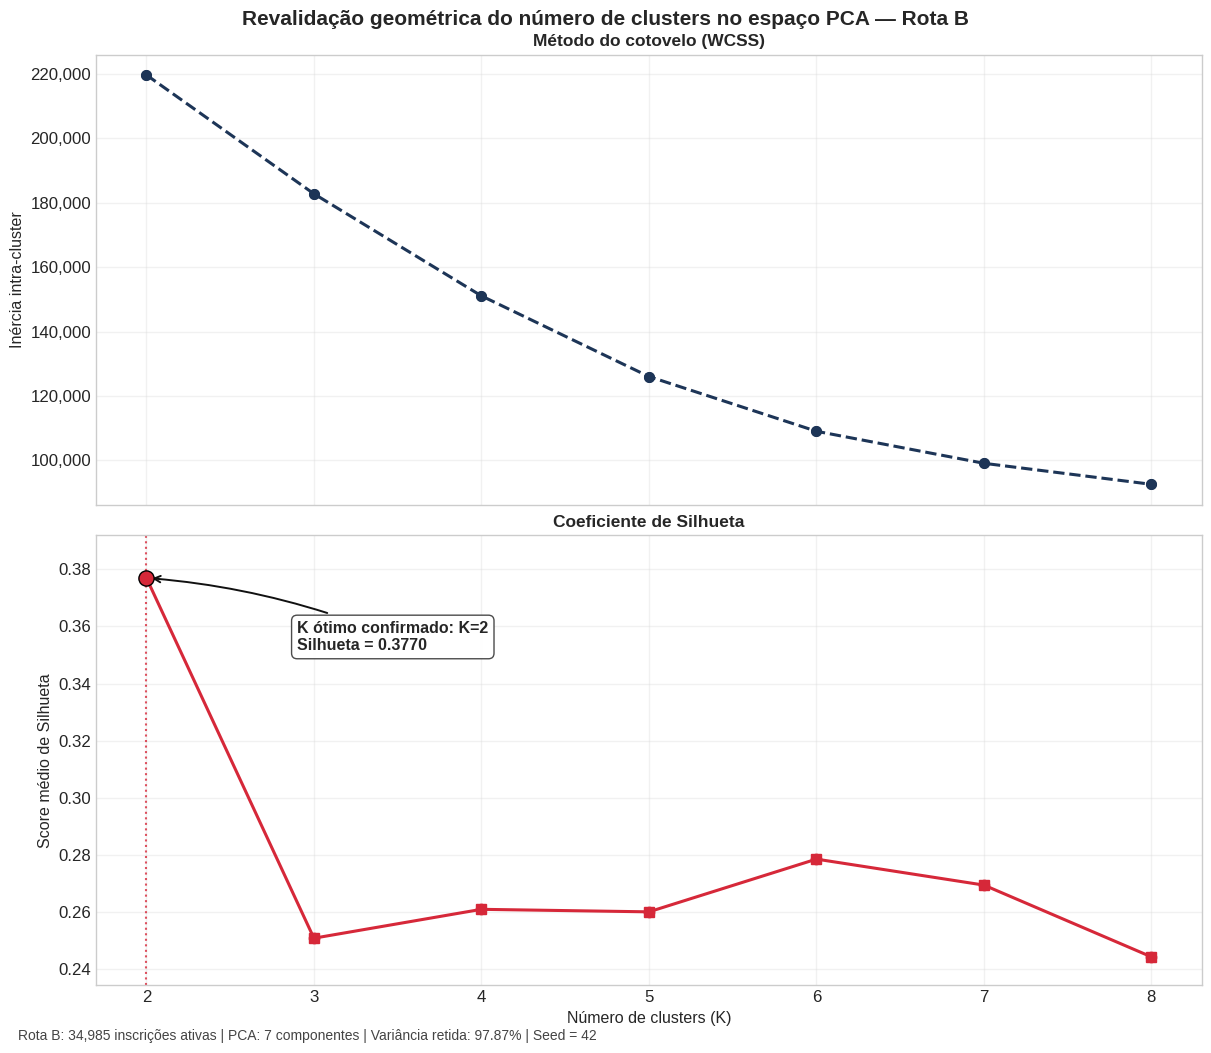


Arquivos gerados com sucesso:
 - PNG 300 dpi: /content/dados_output/figuras/rota_b_revalidacao_pca_vertical_300dpi.png


In [24]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")

print("Carregando base analítica consolidada...")
df = pd.read_parquet(f'{output_path}/matriz_analitica_kdd_final.parquet')

print("Filtrando Rota B (engajamento validado sem imputação em nota e tempo)...")
df_rotab = df[(df['flg_nota_imputada'] == 0) & (df['flg_tempo_imputado'] == 0)].copy()

features_ml = [
    'Idade',
    'Escolaridade_Ordinal',
    'qtd_tentativas',
    'progresso_kdd',
    'nota_final_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p',
    'dias_duracao_curso'
]

faltantes = [c for c in features_ml if c not in df_rotab.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes na base: {faltantes}")

print(f"Rota B preparada com {len(df_rotab):,} registros.")

print("Aplicando padronização Z-score...")
Xb = df_rotab[features_ml].copy()
Xb_scaled = StandardScaler().fit_transform(Xb)

print("Aplicando PCA com retenção mínima de 95% da variância...")
pca = PCA(n_components=0.95, random_state=42)
X_pca_b = pca.fit_transform(Xb_scaled)

n_comp = pca.n_components_
var_retida = pca.explained_variance_ratio_.sum() * 100

print(f"Dimensionalidade reduzida: {Xb.shape[1]} -> {n_comp} componentes.")
print(f"Variância retida: {var_retida:.2f}%")

print("-" * 70)
print("Revalidando as métricas geométricas no subespaço PCA da Rota B...")
print("Calculando WCSS e Silhouette para K de 2 a 8.")
print("-" * 70)

inicio_tempo = time.time()

intervalo_k = list(range(2, 9))
inercia_pca = []
silhueta_pca = []

for k in intervalo_k:
    print(f"Treinando modelo no espaço PCA para K={k}...")
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels_pca = kmeans.fit_predict(X_pca_b)

    inertia_val = kmeans.inertia_
    sil_val = silhouette_score(X_pca_b, labels_pca)

    inercia_pca.append(inertia_val)
    silhueta_pca.append(sil_val)

    print(f"   -> Concluído K={k} | Inércia: {inertia_val:,.0f} | Silhueta: {sil_val:.4f}")

tempo_total = (time.time() - inicio_tempo) / 60
print("\n" + "=" * 70)
print(f"REVALIDAÇÃO CONCLUÍDA EM {tempo_total:.1f} MINUTOS.")
print("-" * 70)

k_max_sil_pca = intervalo_k[int(np.argmax(silhueta_pca))]
max_sil_val_pca = max(silhueta_pca)
plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True
)

fig.suptitle(
    'Revalidação geométrica do número de clusters no espaço PCA — Rota B',
    fontsize=15,
    fontweight='bold',
    y=1.02
)

cores = {
    "inercia": "#1d3557",
    "silhueta": "#d62839",
    "destaque": "#111111",
    "grade": "#d9d9d9"
}

# Gráfico 1: Cotovelo
axes[0].plot(
    intervalo_k, inercia_pca,
    marker='o', linestyle='--',
    color=cores["inercia"],
    linewidth=2.2, markersize=7
)
axes[0].scatter(intervalo_k, inercia_pca, color=cores["inercia"], s=45, zorder=3)
axes[0].set_title('Método do cotovelo (WCSS)', fontsize=12.5, fontweight='bold')
axes[0].set_ylabel('Inércia intra-cluster', fontsize=11.5)
axes[0].grid(True, alpha=0.35, color=cores["grade"])
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:,.0f}'))

# Gráfico 2: Silhueta
axes[1].plot(
    intervalo_k, silhueta_pca,
    marker='s', linestyle='-',
    color=cores["silhueta"],
    linewidth=2.2, markersize=7
)
axes[1].scatter(intervalo_k, silhueta_pca, color=cores["silhueta"], s=55, zorder=3)
axes[1].scatter(
    [k_max_sil_pca], [max_sil_val_pca],
    color=cores["silhueta"], s=120,
    edgecolor='black', linewidth=1.0, zorder=5
)
axes[1].axvline(
    x=k_max_sil_pca,
    color=cores["silhueta"],
    linestyle=':',
    linewidth=1.5,
    alpha=0.8
)

axes[1].set_title('Coeficiente de Silhueta', fontsize=12.5, fontweight='bold')
axes[1].set_xlabel('Número de clusters (K)', fontsize=11.5)
axes[1].set_ylabel('Score médio de Silhueta', fontsize=11.5)
axes[1].set_xticks(intervalo_k)
axes[1].grid(True, alpha=0.35, color=cores["grade"])

margem_inf = max(0, min(silhueta_pca) - 0.01)
margem_sup = max(silhueta_pca) + 0.015
axes[1].set_ylim(margem_inf, margem_sup)

texto_anotacao = (
    f"K ótimo confirmado: K={k_max_sil_pca}\n"
    f"Silhueta = {max_sil_val_pca:.4f}"
)

axes[1].annotate(
    texto_anotacao,
    xy=(k_max_sil_pca, max_sil_val_pca),
    xytext=(k_max_sil_pca + 0.9, max_sil_val_pca - 0.015),
    textcoords='data',
    fontsize=11.5,
    fontweight='bold',
    ha='left',
    va='top',
    bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='#444444', alpha=0.96),
    arrowprops=dict(
        arrowstyle='->',
        color=cores["destaque"],
        lw=1.4,
        shrinkA=4,
        shrinkB=4,
        connectionstyle='arc3,rad=0.08'
    )
)

fig.text(
    0.01, -0.01,
    f"Rota B: {len(df_rotab):,} inscrições ativas | PCA: {n_comp} componentes | Variância retida: {var_retida:.2f}% | Seed = 42",
    fontsize=10,
    color="#444444"
)

output_dir = output_path + "/figuras"
os.makedirs(output_dir, exist_ok=True)

arquivo_png = os.path.join(output_dir, "rota_b_revalidacao_pca_vertical_300dpi.png")

fig.savefig(
    arquivo_png,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("\nArquivos gerados com sucesso:")
print(f" - PNG 300 dpi: {arquivo_png}")


In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
import pandas as pd

print("Executando triangulação de métricas internas (K=2 a K=8 no subespaço PCA)...")
print("-" * 70)

resultados_triangulacao = []
intervalo_teste = range(2, 9)

for k in intervalo_teste:
    # Instanciação e treinamento do modelo no espaço ortogonal
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(X_pca_b)

    # Cálculo dos índices complementares de validação espacial
    ch_score = calinski_harabasz_score(X_pca_b, labels_temp)
    db_score = davies_bouldin_score(X_pca_b, labels_temp)

    # Recuperação do coeficiente de silhueta da iteração anterior (ajuste de índice)
    sil_score = silhueta_pca[k-2]

    resultados_triangulacao.append({
        'K': k,
        'Silhueta (Máx)': round(sil_score, 4),
        'Calinski-Harabasz (Máx)': round(ch_score, 1),
        'Davies-Bouldin (Mín)': round(db_score, 4)
    })

# Estruturação e exibição da matriz de resultados
df_triangulacao = pd.DataFrame(resultados_triangulacao).set_index('K')
print("[QUADRO DE VALIDAÇÃO ESTATÍSTICA CRUZADA]")
# [ALTERAÇÃO 2] Try/except para display() com fallback para print().
try:
    display(df_triangulacao)
except NameError:
    print(df_triangulacao)

print("\n[DIRETRIZES DE INTERPRETAÇÃO]")
print("1. O hiperparâmetro ótimo de K deve demonstrar convergência entre as métricas.")
print("2. Busca-se a maximização simultânea da Silhueta e do índice Calinski-Harabasz,")
print("   alinhada à minimização geométrica do índice Davies-Bouldin.")

Executando triangulação de métricas internas (K=2 a K=8 no subespaço PCA)...
----------------------------------------------------------------------
[QUADRO DE VALIDAÇÃO ESTATÍSTICA CRUZADA]


,Silhueta (Máx),Calinski-Harabasz (Máx),Davies-Bouldin (Mín)
K,,,
2,0.3770,8645.0,1.2835
3,0.2508,8723.6,1.5491
4,0.2609,9480.3,1.2464
5,0.2600,10258.1,1.1792
6,0.2785,10573.0,1.1275
7,0.2694,10278.8,1.1583
8,0.2443,9783.5,1.1727



[DIRETRIZES DE INTERPRETAÇÃO]
1. O hiperparâmetro ótimo de K deve demonstrar convergência entre as métricas.
2. Busca-se a maximização simultânea da Silhueta e do índice Calinski-Harabasz,
   alinhada à minimização geométrica do índice Davies-Bouldin.


## 4. Modelagem Não Supervisionada: K-Means no Espaço Ortogonal

[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]
   -> Cluster 0: 30,698 inscrições (87.7%)
   -> Cluster 1: 4,287 inscrições (12.3%)

GERANDO PROJEÇÃO GEOMÉTRICA 3D (ROTA B)
----------------------------------------------------------------------


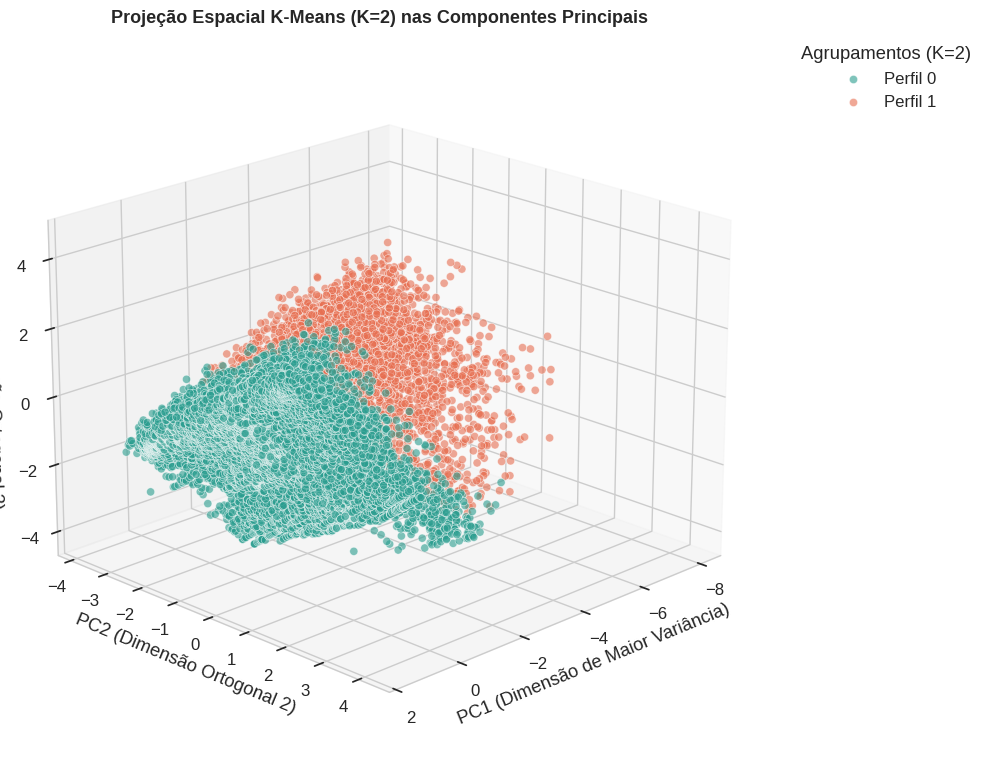


[DIRETRIZ DE TRANSIÇÃO: CARACTERIZAÇÃO PEDAGÓGICA]
-> O algoritmo concluiu o particionamento matemático com sucesso.


In [26]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd
import numpy as np

# 1. Treinamento e Predição Espacial
kmeans_pca = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=10)
clusters_k2 = kmeans_pca.fit_predict(X_pca_b)

# 2. Reintegração dos Rótulos à Matriz Original (Para Profiling Pedagógico)
df_rota_b['Cluster_K2'] = clusters_k2

# Extração das 3 Componentes Principais primárias para projeção gráfica
df_rota_b['PC1'] = X_pca_b[:, 0]
df_rota_b['PC2'] = X_pca_b[:, 1]
df_rota_b['PC3'] = X_pca_b[:, 2]

# 3. Dimensionamento Demográfico dos Agrupamentos
distribuicao = df_rota_b['Cluster_K2'].value_counts().sort_index()
print("[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]")
for cluster, count in distribuicao.items():
    print(f"   -> Cluster {cluster}: {count:,} inscrições ({(count/len(df_rota_b))*100:.1f}%)")

print("\n" + "=" * 70)
print("GERANDO PROJEÇÃO GEOMÉTRICA 3D (ROTA B)")
print("-" * 70)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

# Paleta de cores acadêmica para contraste binário
cores = ['#2a9d8f', '#e76f51']
nomes_clusters = ['Perfil 0', 'Perfil 1']

# Plotagem iterativa para consolidação da legenda
for i in range(2):
    idx = df_rota_b['Cluster_K2'] == i
    ax.scatter(df_rota_b.loc[idx, 'PC1'],
               df_rota_b.loc[idx, 'PC2'],
               df_rota_b.loc[idx, 'PC3'],
               c=cores[i], label=nomes_clusters[i], s=35, alpha=0.6, edgecolors='w', linewidth=0.5)

ax.set_title('Projeção Espacial K-Means (K=2) nas Componentes Principais', fontweight='bold', fontsize=13)
ax.set_xlabel('PC1 (Dimensão de Maior Variância)')
ax.set_ylabel('PC2 (Dimensão Ortogonal 2)')
ax.set_zlabel('PC3 (Dimensão Ortogonal 3)')
ax.legend(title="Agrupamentos (K=2)", bbox_to_anchor=(1.05, 1), loc='upper left')

# Ajuste do ângulo azimutal para otimização da visualização das fronteiras
ax.view_init(elev=20, azim=45)

plt.tight_layout()
plt.show()

print("\n[DIRETRIZ DE TRANSIÇÃO: CARACTERIZAÇÃO PEDAGÓGICA]")
print("-> O algoritmo concluiu o particionamento matemático com sucesso.")

### Painel geométrico dos agrupamentos no subespaço PCA

Carregando base analítica consolidada...
Filtrando Rota B (engajamento validado sem imputação em nota e tempo)...
Rota B preparada com 34,985 registros.
Aplicando padronização Z-score e PCA...
PCA concluído: 8 -> 7 componentes | Variância retida = 97.87%
Instanciando K-Means (K=2) sobre o subespaço ortogonal...

[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]
   -> Cluster 0: 30,698 inscrições (87.7%)
   -> Cluster 1: 4,287 inscrições (12.3%)


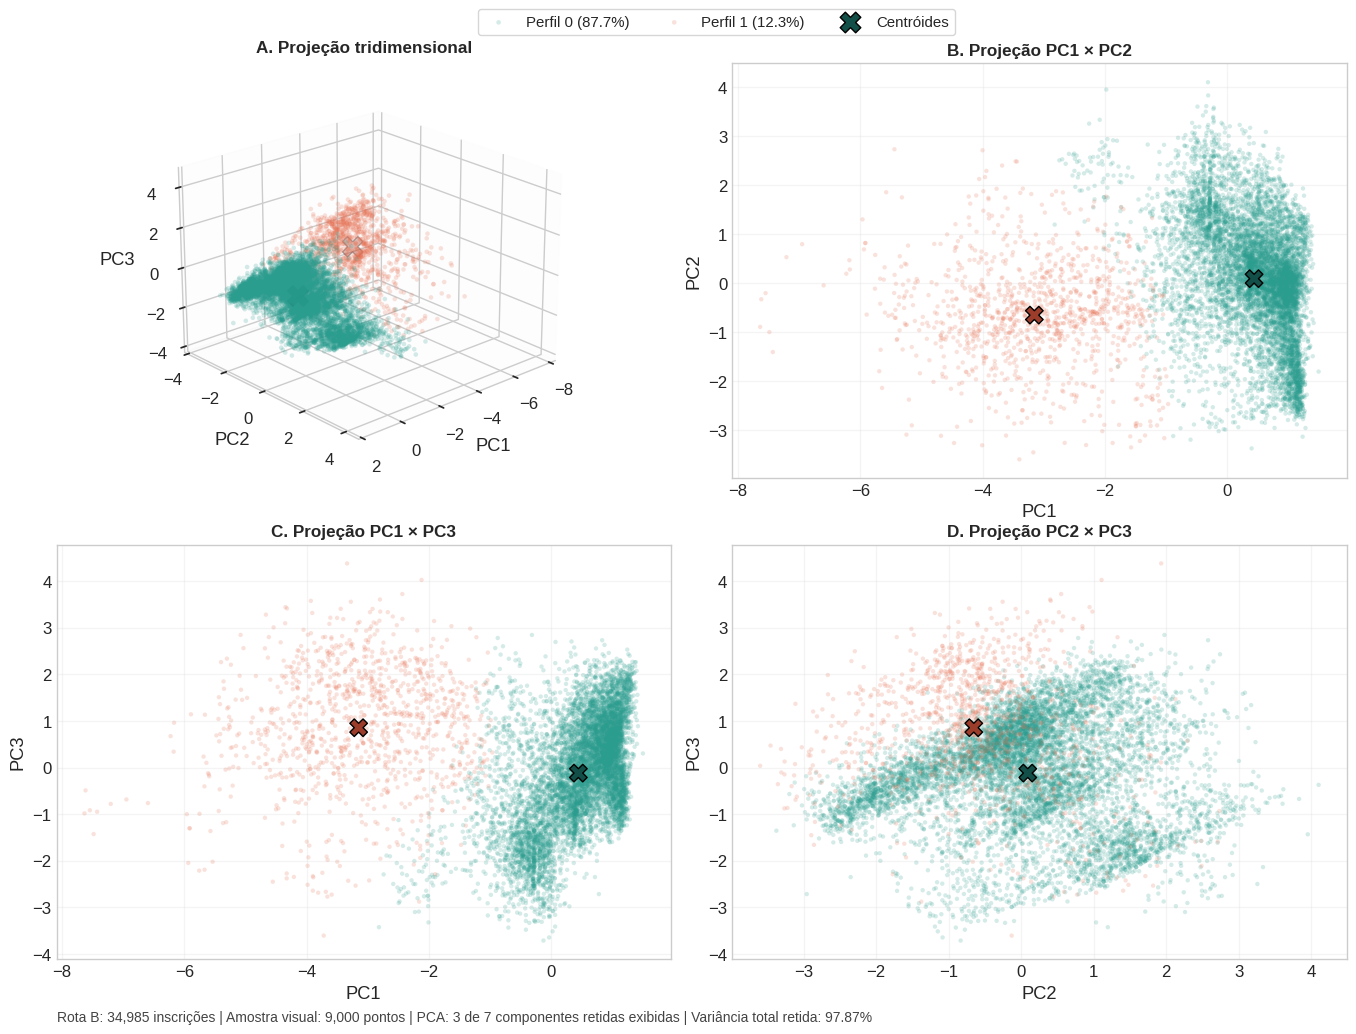


Arquivo gerado com sucesso:
 - PNG 300 dpi: /content/dados_output/figuras/rota_b_painel_3d_2d_percentuais_legenda_300dpi.png


In [27]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

print("Carregando base analítica consolidada...")
df = pd.read_parquet(f'{output_path}/matriz_analitica_kdd_final.parquet')

print("Filtrando Rota B (engajamento validado sem imputação em nota e tempo)...")
df_rota_b = df[(df['flg_nota_imputada'] == 0) & (df['flg_tempo_imputado'] == 0)].copy()

features_ml = [
    'Idade',
    'Escolaridade_Ordinal',
    'qtd_tentativas',
    'progresso_kdd',
    'nota_final_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p',
    'dias_duracao_curso'
]

faltantes = [c for c in features_ml if c not in df_rota_b.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes na base: {faltantes}")

print(f"Rota B preparada com {len(df_rota_b):,} registros.")

print("Aplicando padronização Z-score e PCA...")
X = df_rota_b[features_ml].copy()
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=0.95, random_state=42)
X_pca_b = pca.fit_transform(X_scaled)

var_total = pca.explained_variance_ratio_.sum() * 100
print(f"PCA concluído: {X.shape[1]} -> {pca.n_components_} componentes | Variância retida = {var_total:.2f}%")

print("Instanciando K-Means (K=2) sobre o subespaço ortogonal...")
kmeans_pca = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=10)
clusters_k2 = kmeans_pca.fit_predict(X_pca_b)

df_rota_b['Cluster_K2'] = clusters_k2
df_rota_b['PC1'] = X_pca_b[:, 0]
df_rota_b['PC2'] = X_pca_b[:, 1]
df_rota_b['PC3'] = X_pca_b[:, 2]

distribuicao = df_rota_b['Cluster_K2'].value_counts().sort_index()
pct_0 = (distribuicao[0] / len(df_rota_b)) * 100
pct_1 = (distribuicao[1] / len(df_rota_b)) * 100

print("\n[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]")
for cluster, count in distribuicao.items():
    print(f"   -> Cluster {cluster}: {count:,} inscrições ({(count/len(df_rota_b))*100:.1f}%)")

amostra_total = 9000
frac = min(1.0, amostra_total / len(df_rota_b))

df_plot = (
    df_rota_b.groupby('Cluster_K2', group_keys=False)
    .apply(lambda x: x.sample(frac=frac, random_state=42))
    .copy()
)

centroides_pca3 = kmeans_pca.cluster_centers_[:, :3]

plt.style.use('seaborn-v0_8-whitegrid')

cores = {0: '#2a9d8f', 1: '#e76f51'}
cores_centroides = {0: '#124f48', 1: '#9c3d2c'}

labels = {
    0: f'Perfil 0 ({pct_0:.1f}%)',
    1: f'Perfil 1 ({pct_1:.1f}%)'
}

fig = plt.figure(figsize=(15, 11.2))
gs = fig.add_gridspec(
    2, 2,
    left=0.06, right=0.92, top=0.90, bottom=0.10,
    hspace=0.16, wspace=0.10
)

ax3d = fig.add_subplot(gs[0, 0], projection='3d')
ax12 = fig.add_subplot(gs[0, 1])
ax13 = fig.add_subplot(gs[1, 0])
ax23 = fig.add_subplot(gs[1, 1])

for i in [0, 1]:
    idx = df_plot['Cluster_K2'] == i
    ax3d.scatter(
        df_plot.loc[idx, 'PC1'],
        df_plot.loc[idx, 'PC2'],
        df_plot.loc[idx, 'PC3'],
        c=cores[i],
        s=11,
        alpha=0.20,
        edgecolors='none',
        depthshade=False,
        label=labels[i]
    )

ax3d.scatter(
    centroides_pca3[:, 0],
    centroides_pca3[:, 1],
    centroides_pca3[:, 2],
    c=[cores_centroides[0], cores_centroides[1]],
    s=220,
    marker='X',
    edgecolors='black',
    linewidth=1.0,
    label='Centróides'
)

ax3d.set_title('A. Projeção tridimensional', fontsize=12.3, fontweight='bold', pad=8)
ax3d.set_xlabel('PC1', labelpad=6)
ax3d.set_ylabel('PC2', labelpad=6)
ax3d.set_zlabel('PC3', labelpad=6)
ax3d.view_init(elev=22, azim=48)
ax3d.xaxis.pane.set_alpha(0.08)
ax3d.yaxis.pane.set_alpha(0.08)
ax3d.zaxis.pane.set_alpha(0.08)
ax3d.grid(True, alpha=0.20)

def plot_2d(ax, xcol, ycol, xlabel, ylabel, titulo, cx, cy):
    for i in [0, 1]:
        idx = df_plot['Cluster_K2'] == i
        ax.scatter(
            df_plot.loc[idx, xcol],
            df_plot.loc[idx, ycol],
            c=cores[i],
            s=10,
            alpha=0.20,
            edgecolors='none'
        )
    ax.scatter(
        centroides_pca3[:, cx],
        centroides_pca3[:, cy],
        c=[cores_centroides[0], cores_centroides[1]],
        s=160,
        marker='X',
        edgecolors='black',
        linewidth=1.0,
        zorder=5
    )
    ax.set_title(titulo, fontsize=12.3, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.20)

plot_2d(ax12, 'PC1', 'PC2', 'PC1', 'PC2', 'B. Projeção PC1 × PC2', 0, 1)
plot_2d(ax13, 'PC1', 'PC3', 'PC1', 'PC3', 'C. Projeção PC1 × PC3', 0, 2)
plot_2d(ax23, 'PC2', 'PC3', 'PC2', 'PC3', 'D. Projeção PC2 × PC3', 1, 2)

handles, legend_labels = ax3d.get_legend_handles_labels()
leg = fig.legend(
    handles, legend_labels,
    loc='upper center',
    ncol=3,
    bbox_to_anchor=(0.50, 0.955),
    frameon=True,
    fontsize=10.8
)

fig.text(
    0.06, 0.045,
    f"Rota B: {len(df_rota_b):,} inscrições | Amostra visual: {len(df_plot):,} pontos | PCA: 3 de {pca.n_components_} componentes retidas exibidas | Variância total retida: {var_total:.2f}%",
    fontsize=10.0,
    color="#444444"
)

output_dir = output_path + "/figuras"
os.makedirs(output_dir, exist_ok=True)

arquivo_png = os.path.join(output_dir, "rota_b_painel_3d_2d_percentuais_legenda_300dpi.png")

fig.savefig(
    arquivo_png,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("\nArquivo gerado com sucesso:")
print(f" - PNG 300 dpi: {arquivo_png}")


## 5. Caracterização Pedagógica (Profiling): Tradução de Distâncias em Comportamento

[RAIO-X DOS AGRUPAMENTOS: MÉTRICAS CENTRAIS DE COMPORTAMENTO]


,Mediana: Nota Final,Mediana: Progresso (%),Horas_Reais_Medianas,Dias_Reais_Medianos,Mediana: Tentativas,Mediana: Idade
Cluster_K2,,,,,,
0,96.0,100.00,12.5,11.0,1.0,42.0
1,30.5,44.83,6.6,6.0,1.0,42.0



GERANDO ANÁLISE VISUAL DE DISTRIBUIÇÃO ESPACIAL (BOXPLOTS)
----------------------------------------------------------------------


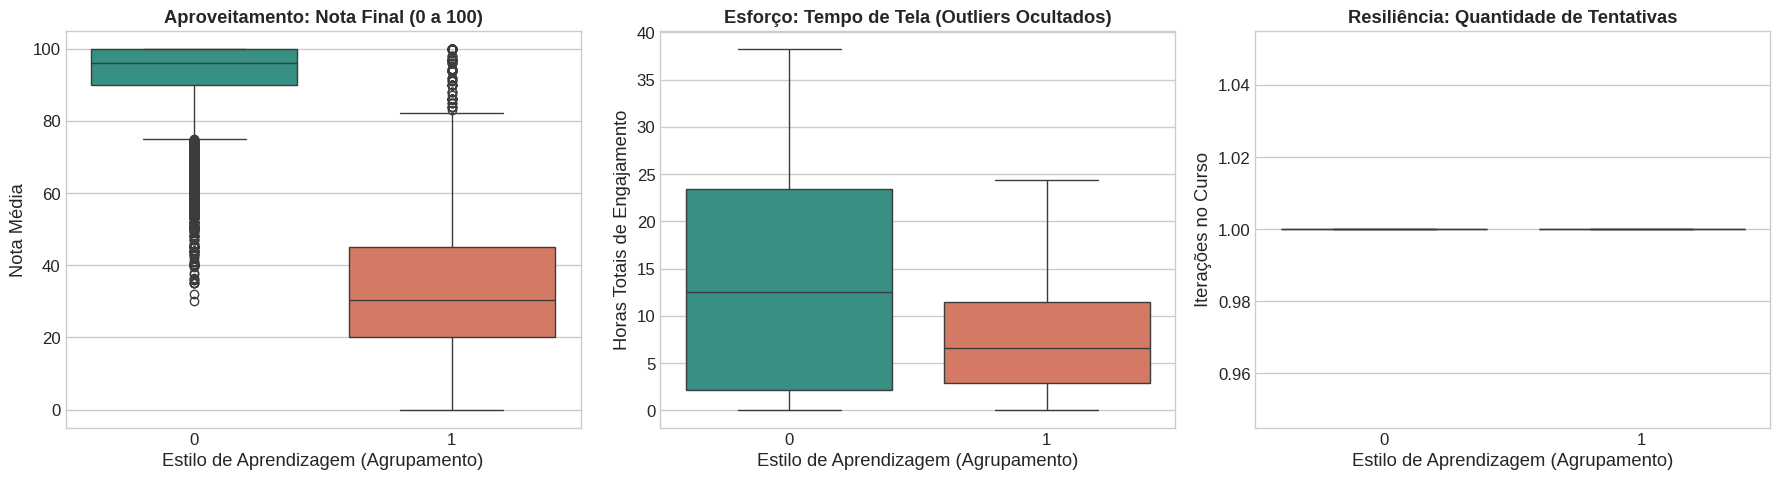


[DIRETRIZ DE TRANSIÇÃO: A NOMENCLATURA PEDAGÓGICA]


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# 1. Definição das variáveis de interesse e cálculo de Medianas (robustez a outliers)
colunas_perfil = [
    'nota_final_kdd',
    'progresso_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p',
    'qtd_tentativas',
    'Idade'
]

# Agrupamento pelas predições do K-Means (K=2)
df_perfil = df_rota_b.groupby('Cluster_K2')[colunas_perfil].median()

# 2. Reversão Matemática das Transformações Logarítmicas (Exponencial Inversa)
df_perfil['Horas_Reais_Medianas'] = (np.expm1(df_perfil['minutos_totais_log1p']) / 60).round(1)
df_perfil['Dias_Reais_Medianos'] = np.expm1(df_perfil['dias_permanencia_log1p']).round(1)

# Limpeza e renomeação do DataFrame para apresentação no relatório final
df_perfil = df_perfil.drop(columns=['minutos_totais_log1p', 'dias_permanencia_log1p'])
df_perfil = df_perfil.rename(columns={
    'nota_final_kdd': 'Mediana: Nota Final',
    'progresso_kdd': 'Mediana: Progresso (%)',
    'qtd_tentativas': 'Mediana: Tentativas',
    'Idade': 'Mediana: Idade'
})

# Reordenando as colunas para melhor fluxo de leitura
df_perfil = df_perfil[['Mediana: Nota Final', 'Mediana: Progresso (%)',
                       'Horas_Reais_Medianas', 'Dias_Reais_Medianos',
                       'Mediana: Tentativas', 'Mediana: Idade']]

print("[RAIO-X DOS AGRUPAMENTOS: MÉTRICAS CENTRAIS DE COMPORTAMENTO]")
try:
    display(df_perfil)
except NameError:
    print(df_perfil)

print("\n" + "=" * 70)
print("GERANDO ANÁLISE VISUAL DE DISTRIBUIÇÃO ESPACIAL (BOXPLOTS)")
print("-" * 70)

# Criação de coluna temporária de horas reais para a plotagem
df_rota_b['horas_reais_plot'] = np.expm1(df_rota_b['minutos_totais_log1p']) / 60

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cores_clusters = ['#2a9d8f', '#e76f51']  # Paleta binária acadêmica

# Gráfico 1: Aproveitamento Acadêmico (Nota Final)
sns.boxplot(x='Cluster_K2', y='nota_final_kdd', hue='Cluster_K2', data=df_rota_b, ax=axes[0], palette=cores_clusters, legend=False)
axes[0].set_title('Aproveitamento: Nota Final (0 a 100)', fontweight='bold')
axes[0].set_xlabel('Estilo de Aprendizagem (Agrupamento)')
axes[0].set_ylabel('Nota Média')

# Gráfico 2: Esforço Comportamental (Horas Reais)
sns.boxplot(x='Cluster_K2', y='horas_reais_plot', hue='Cluster_K2', data=df_rota_b, ax=axes[1], palette=cores_clusters, legend=False, showfliers=False)
axes[1].set_title('Esforço: Tempo de Tela (Outliers Ocultados)', fontweight='bold')
axes[1].set_xlabel('Estilo de Aprendizagem (Agrupamento)')
axes[1].set_ylabel('Horas Totais de Engajamento')

# Gráfico 3: Resiliência (Quantidade de Tentativas)
sns.boxplot(x='Cluster_K2', y='qtd_tentativas', hue='Cluster_K2', data=df_rota_b, ax=axes[2], palette=cores_clusters, legend=False, showfliers=False)
axes[2].set_title('Resiliência: Quantidade de Tentativas', fontweight='bold')
axes[2].set_xlabel('Estilo de Aprendizagem (Agrupamento)')
axes[2].set_ylabel('Iterações no Curso')

plt.tight_layout()
plt.show()

print("\n[DIRETRIZ DE TRANSIÇÃO: A NOMENCLATURA PEDAGÓGICA]")



GERANDO BOXPLOTS HORIZONTAIS DE PROFILING (LADO A LADO)
----------------------------------------------------------------------


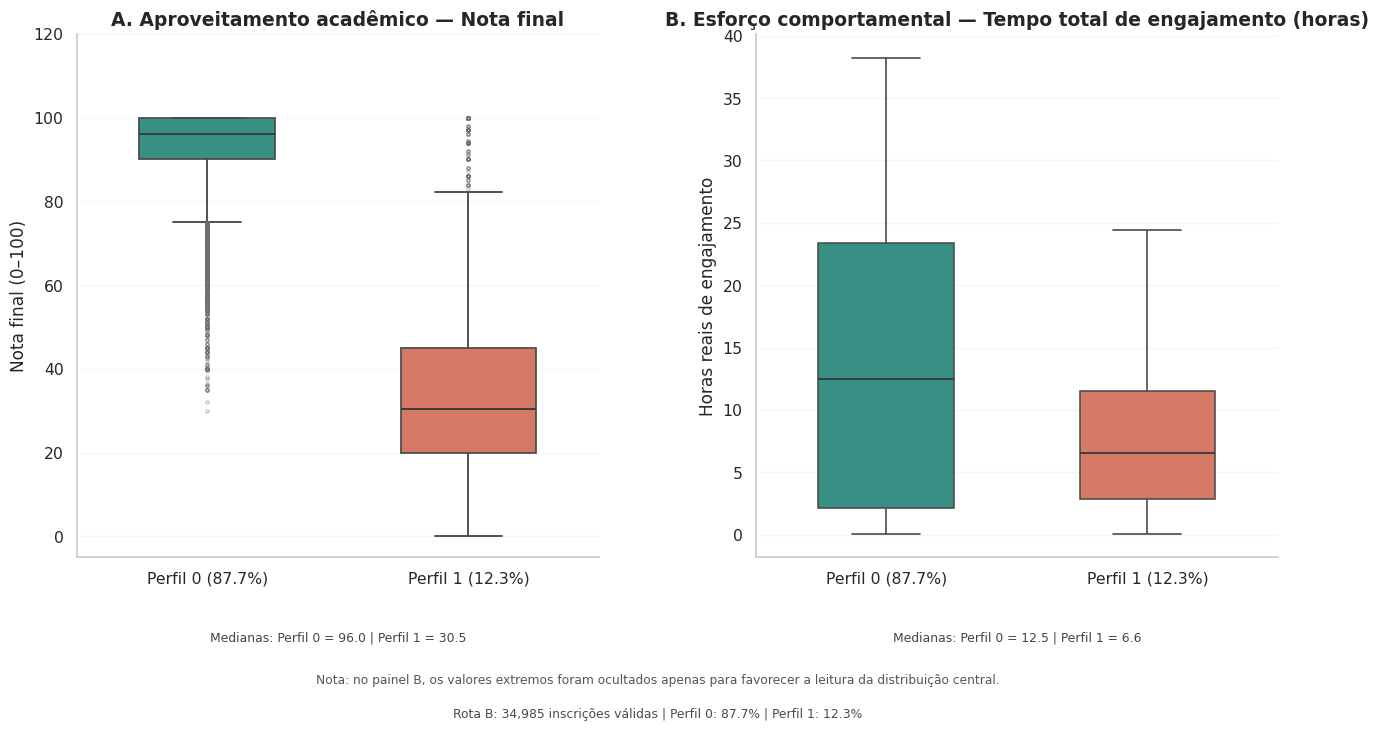


Arquivo gerado com sucesso:
 - PNG 300 dpi: /content/dados_output/figuras/rota_b_boxplots_profiling_horizontal_espacamento_final_300dpi.png


In [29]:
print("\n" + "=" * 70)
print("GERANDO BOXPLOTS HORIZONTAIS DE PROFILING (LADO A LADO)")
print("-" * 70)

# --- Variáveis necessárias para o plot (garantindo que a célula seja autossuficiente) ---
df_rota_b['Horas_Reais_Engajamento'] = np.expm1(df_rota_b['minutos_totais_log1p']) / 60

distribuicao = df_rota_b['Cluster_K2'].value_counts().sort_index()
pct = (distribuicao / len(df_rota_b) * 100).round(1)

labels_clusters = {
    0: f"Perfil 0 ({pct.loc[0]:.1f}%)",
    1: f"Perfil 1 ({pct.loc[1]:.1f}%)"
}
df_rota_b['Perfil_Label'] = df_rota_b['Cluster_K2'].map(labels_clusters)

ordem = [labels_clusters[0], labels_clusters[1]]
cores = ['#2a9d8f', '#e76f51']
# ------------------------------------------------------------------------------------

sns.set_theme(style="whitegrid", font_scale=1.02)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15.5, 6.8),
    gridspec_kw={'wspace': 0.30}
)

sns.boxplot(
    x='Perfil_Label',
    y='nota_final_kdd',
    hue='Perfil_Label',
    data=df_rota_b,
    ax=axes[0],
    palette=cores,
    order=ordem,
    legend=False,
    width=0.52,
    linewidth=1.25,
    boxprops=dict(edgecolor='#4a4a4a', linewidth=1.25),
    whiskerprops=dict(color='#4a4a4a', linewidth=1.35),
    capprops=dict(color='#4a4a4a', linewidth=1.35),
    medianprops=dict(color='#3b3b3b', linewidth=1.4),
    flierprops=dict(
        marker='o',
        markersize=2.2,
        markerfacecolor='none',
        markeredgecolor='#707070',
        alpha=0.40
    )
)

axes[0].set_title('A. Aproveitamento acadêmico — Nota final', fontsize=13.5, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Nota final (0–100)')
axes[0].set_ylim(-5, 120)
axes[0].set_yticks(np.arange(0, 121, 20))
axes[0].grid(True, axis='y', alpha=0.18)

sns.boxplot(
    x='Perfil_Label',
    y='Horas_Reais_Engajamento',
    hue='Perfil_Label',
    data=df_rota_b,
    ax=axes[1],
    palette=cores,
    order=ordem,
    legend=False,
    width=0.52,
    linewidth=1.15,
    boxprops=dict(edgecolor='#4a4a4a', linewidth=1.15),
    whiskerprops=dict(color='#4a4a4a', linewidth=1.20),
    capprops=dict(color='#4a4a4a', linewidth=1.20),
    medianprops=dict(color='#3b3b3b', linewidth=1.35),
    showfliers=False
)

axes[1].set_title('B. Esforço comportamental — Tempo total de engajamento (horas)', fontsize=13.5, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Horas reais de engajamento')
axes[1].grid(True, axis='y', alpha=0.18)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()

med_nota_0 = df_rota_b.loc[df_rota_b['Perfil_Label'] == ordem[0], 'nota_final_kdd'].median()
med_nota_1 = df_rota_b.loc[df_rota_b['Perfil_Label'] == ordem[1], 'nota_final_kdd'].median()

med_tempo_0 = df_rota_b.loc[df_rota_b['Perfil_Label'] == ordem[0], 'Horas_Reais_Engajamento'].median()
med_tempo_1 = df_rota_b.loc[df_rota_b['Perfil_Label'] == ordem[1], 'Horas_Reais_Engajamento'].median()

axes[0].text(
    0.5, -0.14,
    f"Medianas: Perfil 0 = {med_nota_0:.1f} | Perfil 1 = {med_nota_1:.1f}",
    transform=axes[0].transAxes,
    ha='center', va='top',
    fontsize=8.9, color='#444444'
)

axes[1].text(
    0.5, -0.14,
    f"Medianas: Perfil 0 = {med_tempo_0:.1f} | Perfil 1 = {med_tempo_1:.1f}",
    transform=axes[1].transAxes,
    ha='center', va='top',
    fontsize=8.9, color='#444444'
)

fig.text(
    0.5, -0.06,
    "Nota: no painel B, os valores extremos foram ocultados apenas para favorecer a leitura da distribuição central.",
    ha='center', va='top',
    fontsize=8.8, color="#555555"
)

fig.text(
    0.5, -0.11,
    f"Rota B: {len(df_rota_b):,} inscrições válidas | Perfil 0: {pct.loc[0]:.1f}% | Perfil 1: {pct.loc[1]:.1f}%",
    ha='center', va='top',
    fontsize=8.9, color="#4a4a4a"
)

output_dir = output_path + "/figuras"
os.makedirs(output_dir, exist_ok=True)
arquivo_png = os.path.join(output_dir, "rota_b_boxplots_profiling_horizontal_espacamento_final_300dpi.png")

fig.savefig(
    arquivo_png,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("\nArquivo gerado com sucesso:")
print(f" - PNG 300 dpi: {arquivo_png}")

## 6. Consolidação e Exportação do Espaço Vetorial Rotulado

In [30]:
import pandas as pd

print("Iniciando a consolidação da matriz rotulada (Rota B)...")
print("-" * 70)

# 1. Mapeamento da Taxonomia Pedagógica (K=2)
mapa_taxonomia = {
    0: 'Perfil 0: Engajamento Pleno e Alta Eficiência',
    1: 'Perfil 1: Atrito Intermediário e Evasão Parcial'
}

# 2. Criação da dimensão categórica de classificação
df_rota_b['Persona_Educacional'] = df_rota_b['Cluster_K2'].map(mapa_taxonomia)

# 3. Ordenação Estratégica das Colunas
# Realocação das chaves de classificação para o início do DataFrame
colunas_atuais = df_rota_b.columns.tolist()
colunas_prioritarias = ['Persona_Educacional', 'Cluster_K2', 'PC1', 'PC2', 'PC3']

colunas_restantes = [col for col in colunas_atuais if col not in colunas_prioritarias]
nova_ordem = colunas_prioritarias + colunas_restantes
df_final_exportacao = df_rota_b[nova_ordem].copy()

print("[AMOSTRA DA MATRIZ ANALÍTICA FINAL]")
try:
    display(df_final_exportacao[['Persona_Educacional', 'Idade', 'qtd_tentativas', 'nota_final_kdd', 'progresso_kdd']].head())
except NameError:
    print(df_final_exportacao[['Persona_Educacional', 'Idade', 'qtd_tentativas', 'nota_final_kdd', 'progresso_kdd']].head())

print("\n" + "=" * 70)
print("SALVANDO ARTEFATOS NO DIRETÓRIO LOCAL")
print("-" * 70)

caminho_parquet = output_path + '/matriz_rota_b_clusterizada.parquet'
caminho_csv = output_path + '/matriz_rota_b_clusterizada.csv'

try:
    # Exportação Parquet (Padrão de Engenharia de Dados)
    df_final_exportacao.to_parquet(caminho_parquet, index=False)

    # Exportação CSV (Padrão de Gestão/BI - Formatação PT-BR)
    df_final_exportacao.to_csv(caminho_csv, index=False, sep=';', decimal=',')

    print("[SUCESSO] Arquivos exportados com exatidão metodológica.")
    print(f"-> Formato Parquet: {caminho_parquet}")
    print(f"-> Formato CSV: {caminho_csv}")

except Exception as e:
    print(f"[ERRO] Falha durante a exportação: {e}")


Iniciando a consolidação da matriz rotulada (Rota B)...
----------------------------------------------------------------------
[AMOSTRA DA MATRIZ ANALÍTICA FINAL]


,Persona_Educacional,Idade,qtd_tentativas,nota_final_kdd,progresso_kdd
0,Perfil 0: Engajamento Pleno e Alta Eficiência,32.0,1,90.0,100.0
1,Perfil 0: Engajamento Pleno e Alta Eficiência,25.0,1,100.0,100.0
3,Perfil 0: Engajamento Pleno e Alta Eficiência,44.0,1,100.0,100.0
4,Perfil 0: Engajamento Pleno e Alta Eficiência,54.0,1,100.0,100.0
6,Perfil 0: Engajamento Pleno e Alta Eficiência,42.0,1,100.0,100.0



SALVANDO ARTEFATOS NO DIRETÓRIO LOCAL
----------------------------------------------------------------------
[SUCESSO] Arquivos exportados com exatidão metodológica.
-> Formato Parquet: /content/dados_output/matriz_rota_b_clusterizada.parquet
-> Formato CSV: /content/dados_output/matriz_rota_b_clusterizada.csv


## 7. Análise Post-Hoc: Cruzamento Geográfico e Demográfico

[MATRIZ DE CONTINGÊNCIA: DISTRIBUIÇÃO PERCENTUAL POR SRE]


Persona_Educacional,Perfil 0: Engajamento Pleno e Alta Eficiência,Perfil 1: Atrito Intermediário e Evasão Parcial
SRE,,
NAO_INFORMADO_EXTERNO,89.8,10.2
SRE AFONSO CLÁUDIO,88.7,11.3
SRE BARRA DE SÃO FRANCISCO,88.6,11.4
SRE CACHOEIRO DE ITAPEMIRIM,87.8,12.2
SRE CARAPINA,87.0,13.0
SRE CARIACICA,83.2,16.8
SRE COLATINA,89.5,10.5
SRE COMENDADORA JUREMA MORETZ SOHN,88.4,11.6
SRE LINHARES,86.7,13.3


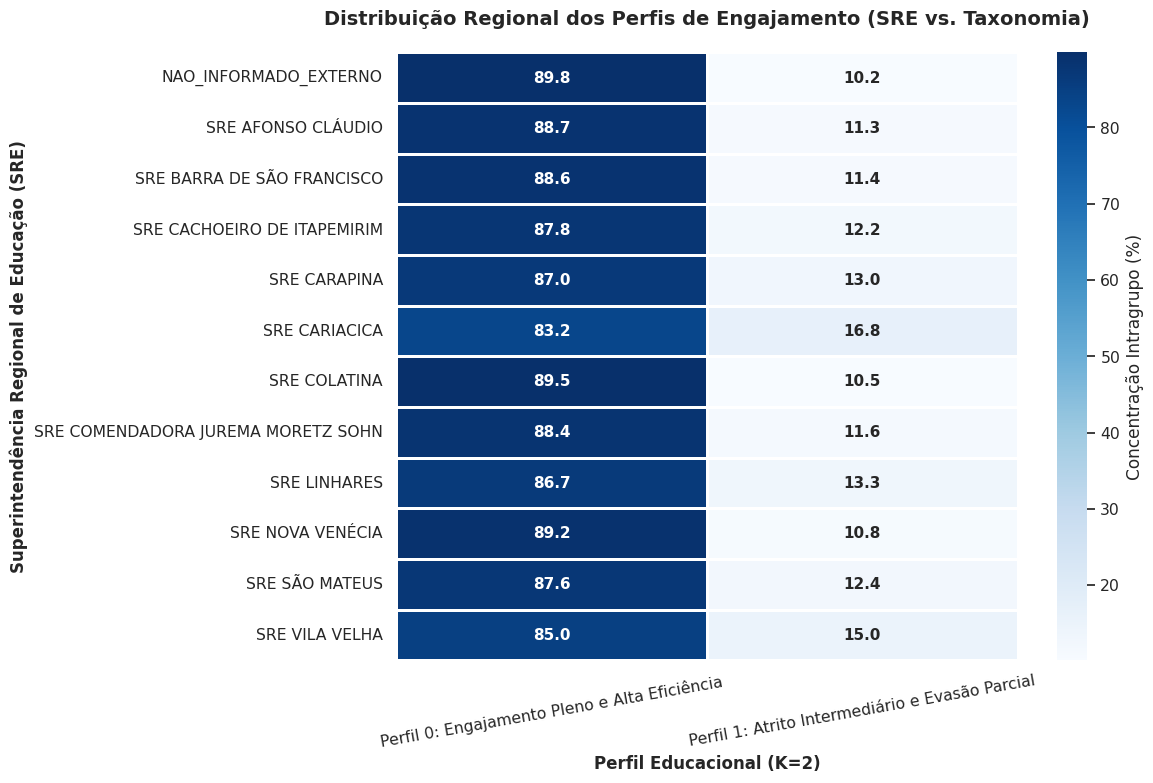

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Criação da matriz de contingência (frequência absoluta) e conversão para percentual (linha)
tabela_sre = pd.crosstab(df_final_exportacao['SRE'], df_final_exportacao['Persona_Educacional'])
tabela_sre_pct = tabela_sre.div(tabela_sre.sum(axis=1), axis=0) * 100

# 2. Ordenação das colunas alinhada à taxonomia binária
ordem_colunas = [
    'Perfil 0: Engajamento Pleno e Alta Eficiência',
    'Perfil 1: Atrito Intermediário e Evasão Parcial'
]

# Proteção contra KeyErrors caso os nomes divirjam sutilmente
ordem_presente = [col for col in ordem_colunas if col in tabela_sre_pct.columns]
tabela_sre_pct = tabela_sre_pct[ordem_presente]

print("[MATRIZ DE CONTINGÊNCIA: DISTRIBUIÇÃO PERCENTUAL POR SRE]")
try:
    display(tabela_sre_pct.round(1))
except NameError:
    print(tabela_sre_pct.round(1))

plt.figure(figsize=(12, 8))

# Utilização da paleta 'Blues' (padrão acadêmico para mapas de densidade sequenciais)
ax = sns.heatmap(tabela_sre_pct, annot=True, fmt=".1f", cmap="Blues",
                 linewidths=1, linecolor='white', cbar_kws={'label': 'Concentração Intragrupo (%)'},
                 annot_kws={"size": 11, "weight": "bold"})

# Parametrização dos eixos e título
plt.title('Distribuição Regional dos Perfis de Engajamento (SRE vs. Taxonomia)',
          fontweight='bold', fontsize=14, pad=20)
plt.ylabel('Superintendência Regional de Educação (SRE)', fontweight='bold', fontsize=12)
plt.xlabel('Perfil Educacional (K=2)', fontweight='bold', fontsize=12)

# Ajuste da rotação para acomodar as nomenclaturas dos agrupamentos
plt.xticks(rotation=10, ha='center')

plt.tight_layout()
plt.show()


## 8. Análise Post-Hoc: Cruzamento Ocupacional (Atuação Funcional vs. Perfis)

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Validação da existência da variável estruturada
if 'Macro_Cargo' not in df_final_exportacao.columns:
    print("[ERRO] A variável 'Macro_Cargo' não foi encontrada. Verifique o DataFrame.")
else:
    # 2. Criação da matriz de contingência e conversão para percentual (linha)
    tabela_cargo = pd.crosstab(df_final_exportacao['Macro_Cargo'], df_final_exportacao['Persona_Educacional'])
    tabela_cargo_pct = tabela_cargo.div(tabela_cargo.sum(axis=1), axis=0) * 100

    # 3. Ordenação das colunas alinhada à taxonomia binária vigente
    ordem_colunas = [
        'Perfil 0: Engajamento Pleno e Alta Eficiência',
        'Perfil 1: Atrito Intermediário e Evasão Parcial'
    ]

    # Filtro de segurança para as colunas
    ordem_presente = [col for col in ordem_colunas if col in tabela_cargo_pct.columns]
    tabela_cargo_pct = tabela_cargo_pct[ordem_presente]

    print("[MATRIZ DE CONTINGÊNCIA: DISTRIBUIÇÃO PERCENTUAL POR MACRO CARGO]")
try:
    display(tabela_cargo_pct.round(1))
except NameError:
    print(tabela_cargo_pct.round(1))

    plt.figure(figsize=(12, 6))

    ax = sns.heatmap(tabela_cargo_pct, annot=True, fmt=".1f", cmap="Oranges",
                     linewidths=1, linecolor='white', cbar_kws={'label': 'Concentração Intragrupo (%)'},
                     annot_kws={"size": 11, "weight": "bold"})

    plt.title('Distribuição Ocupacional dos Perfis de Engajamento (Cargo vs. Taxonomia)',
              fontweight='bold', fontsize=14, pad=20)
    plt.ylabel('Eixo de Atuação (Macro Cargo)', fontweight='bold', fontsize=12)
    plt.xlabel('Perfil Educacional (K=2)', fontweight='bold', fontsize=12)

    # Rotação sutil do eixo X
    plt.xticks(rotation=10, ha='center')

    plt.tight_layout()
    plt.show()


[MATRIZ DE CONTINGÊNCIA: DISTRIBUIÇÃO PERCENTUAL POR MACRO CARGO]


Persona_Educacional,Perfil 0: Engajamento Pleno e Alta Eficiência,Perfil 1: Atrito Intermediário e Evasão Parcial
Macro_Cargo,,
0_NAO_INFORMADO_OUTROS,87.1,12.9
1_DOCENCIA,88.2,11.8
2_GESTAO_PEDAGOGICO,85.0,15.0
3_APOIO_ESCOLAR,89.1,10.9


## 9. Análise Post-Hoc: Evolução Longitudinal do Engajamento

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Validação da variável temporal na matriz
if 'Ano_Oferta' not in df_final_exportacao.columns:
    print("[ERRO] A coluna 'Ano_Oferta' não foi encontrada. Verifique o DataFrame.")
else:
    # 2. Criação da matriz de contingência temporal (Percentual de Perfis por Ano)
    tabela_ano = pd.crosstab(df_final_exportacao['Ano_Oferta'], df_final_exportacao['Persona_Educacional'])
    tabela_ano_pct = tabela_ano.div(tabela_ano.sum(axis=1), axis=0) * 100

    # 3. Ordenação das colunas alinhada à taxonomia binária (K=2)
    ordem_temporal = [
        'Perfil 0: Engajamento Pleno e Alta Eficiência',
        'Perfil 1: Atrito Intermediário e Evasão Parcial'
    ]

    # Filtro de segurança geométrica
    ordem_presente = [col for col in ordem_temporal if col in tabela_ano_pct.columns]
    tabela_ano_pct = tabela_ano_pct[ordem_presente]

    print("[MATRIZ DE CONTINGÊNCIA: EVOLUÇÃO PERCENTUAL POR ANO DE OFERTA]")
try:
    display(tabela_ano_pct.round(1))
except NameError:
    print(tabela_ano_pct.round(1))

    cores_temporais = ['#2a9d8f', '#e76f51']

    fig, ax = plt.subplots(figsize=(10, 6))

    tabela_ano_pct.plot(kind='bar', stacked=True, color=cores_temporais, ax=ax, edgecolor='white', linewidth=1)

    plt.title('Evolução Longitudinal dos Perfis de Engajamento por Ano de Oferta', fontweight='bold', fontsize=14, pad=15)
    plt.xlabel('Ano de Oferta da Formação', fontweight='bold', fontsize=12)
    plt.ylabel('Composição Proporcional das Inscrições (%)', fontweight='bold', fontsize=12)
    plt.xticks(rotation=0)

    # Inserção de rótulos percentuais no interior das barras para leitura direta
    for c in ax.containers:
        # Oculta rótulos muito pequenos para não comprometer a clareza visual
        labels = [f'{v.get_height():.1f}%' if v.get_height() > 2 else '' for v in c]
        ax.bar_label(c, labels=labels, label_type='center', color='white', fontweight='bold', fontsize=10)

    # Configuração da legenda fora da área de plotagem
    plt.legend(title='Taxonomia Pedagógica (K=2)', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
    plt.tight_layout()
    plt.show()


[MATRIZ DE CONTINGÊNCIA: EVOLUÇÃO PERCENTUAL POR ANO DE OFERTA]


Persona_Educacional,Perfil 0: Engajamento Pleno e Alta Eficiência,Perfil 1: Atrito Intermediário e Evasão Parcial
Ano_Oferta,,
2023,90.2,9.8
2024,83.5,16.5
2025,88.2,11.8


## 10.  AUDITORIA DAS VARIÁVEIS SUBMETIDAS AO PCA (ROTA B)

In [34]:
# ==============================================================================
# AUDITORIA DAS VARIÁVEIS SUBMETIDAS AO PCA (ROTA B)
# Versão robusta — não depende de variáveis pré-definidas
# ==============================================================================
print("AUDITORIA DO ESPAÇO VETORIAL DA ROTA B\n" + "=" * 60)

# 1) Quais colunas compõem a matriz de features que você escala?
#    Substitua X_features pelo nome que você usou na célula do PCA.
#    Exemplos comuns: X, X_rota_b, df_features, etc.
#
#    Para descobrir, execute a linha abaixo com o nome correto:
# print(type(X))         # se for numpy array → .shape revela nº de colunas
# print(df.columns.tolist())  # se for DataFrame → lista os nomes

# 2) Tente inspecionar o escopo atual:
print("Variáveis candidatas a 'features' encontradas no escopo:")
candidates = []
for var_name in ['X', 'X_scaled', 'df_rota_b', 'df_features', 'features', 'cols_features']:
    if var_name in dir():
        obj = eval(var_name)
        if isinstance(obj, (np.ndarray, pd.DataFrame)):
            shape_info = obj.shape[1] if hasattr(obj, 'shape') else len(obj)
            candidates.append((var_name, shape_info))
            print(f"  → {var_name}: {type(obj).__name__} com {shape_info} colunas/variáveis")

if not candidates:
    print("  Nenhuma encontrada. Execute a célula de PCA antes desta auditoria.")
else:
    # Se for DataFrame, liste os nomes das colunas
    for var_name, _ in candidates:
        obj = eval(var_name)
        if isinstance(obj, pd.DataFrame):
            print(f"\n  Colunas de {var_name}:")
            for i, col in enumerate(obj.columns, 1):
                print(f"    {i:2d}. {col}")
            print(f"  Total: {len(obj.columns)} variáveis → {'✅ 8' if len(obj.columns) == 8 else '❌ ≠ 8 (verificar!)'}")

print("\n" + "=" * 60)
print("INSTRUÇÃO: Se a lista de colunas não apareceu acima, você precisa")
print("informar o nome exato da matriz que foi passada ao PCA.fit_transform().")

AUDITORIA DO ESPAÇO VETORIAL DA ROTA B
Variáveis candidatas a 'features' encontradas no escopo:
  → X: DataFrame com 8 colunas/variáveis
  → X_scaled: ndarray com 8 colunas/variáveis
  → df_rota_b: DataFrame com 45 colunas/variáveis

  Colunas de X:
     1. Idade
     2. Escolaridade_Ordinal
     3. qtd_tentativas
     4. progresso_kdd
     5. nota_final_kdd
     6. minutos_totais_log1p
     7. dias_permanencia_log1p
     8. dias_duracao_curso
  Total: 8 variáveis → ✅ 8

  Colunas de df_rota_b:
     1. id_inscricoes
     2. Nome_Breve
     3. Nome_Formacao
     4. carga_horaria
     5. datahora_inscricao
     6. Sexo
     7. data_nascimento
     8. Municipio
     9. Tipo_Instituicao
    10. SRE
    11. id_discente_anonimo
    12. Cargo_imputado
    13. Funcao_imputado
    14. Tipo_Instituicao_imputado
    15. Sexo_imputado
    16. Escolaridade_imputado
    17. teto_curso
    18. carga_horaria_winsor
    19. Idade
    20. Idade_imputado
    21. Macro_Cargo
    22. Escolaridade_Ordinal
 

## 11. AUDITORIA DE VARIÁVEIS NA MEMÓRIA

In [35]:
from sklearn.decomposition import PCA

print("--- AUDITORIA DE VARIÁVEIS NA MEMÓRIA ---")

# 1. Busca por objetos do tipo PCA instanciados
pca_vars = [name for name, val in globals().items() if isinstance(val, PCA)]
print(f"-> Objetos PCA encontrados na memória: {pca_vars}")

# 2. Busca por variáveis que contenham 'pca' no nome (caso o tipo esteja mascarado)
pca_names = [name for name in globals().keys() if 'pca' in name.lower() and not name.startswith('_')]
print(f"-> Variáveis com 'pca' no nome: {pca_names}")

# 3. Busca pela lista de features (para garantir que features_ml existe)
feature_vars = [name for name, val in globals().items() if isinstance(val, list) and 'nota_final_kdd' in val]
print(f"-> Listas de features encontradas: {feature_vars}")

--- AUDITORIA DE VARIÁVEIS NA MEMÓRIA ---
-> Objetos PCA encontrados na memória: ['pca_full', 'pca_opt', 'pca']
-> Variáveis com 'pca' no nome: ['PCA', 'pca_full', 'pca_opt', 'X_pca_b', 'inercia_pca', 'silhueta_pca', 'labels_pca', 'score_sil_pca', 'k_max_sil_pca', 'max_sil_val_pca', 'pca', 'kmeans_pca', 'centroides_pca3', 'pca_vars']
-> Listas de features encontradas: ['features_ml', 'features_ml_existentes', 'colunas_perfil', 'colunas_atuais', 'colunas_restantes', 'nova_ordem']


## 12. Geração da tabela de "Cargas dos Componentes Principais (PCA) - Rota B"

In [36]:
import pandas as pd
from IPython.display import display

# 1. Extração das Cargas (Loadings) da PCA - Rota B
# Utilizando a variável 'pca_opt' identificada na auditoria
cargas_pca_b = pd.DataFrame(
    pca_opt.components_.T,
    columns=[f'PC{i+1}' for i in range(pca_opt.n_components_)],
    index=features_ml
)

print("--- CARGAS DO PCA (ROTA B) ---")
display(cargas_pca_b.round(3))

# 2. Geração do código LaTeX
latex_cargas_b = r"""\begin{table}[htbp]
\centering
\caption{Cargas dos Componentes Principais (PCA) - Rota B}
\label{tab:pca_loadings_b}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l""" + "c" * pca_opt.n_components_ + r"""}
\toprule
\textbf{Variável Original} & """ + " & ".join([f"\\textbf{{PC{i+1}}}" for i in range(pca_opt.n_components_)]) + r""" \\
\midrule
"""

# Preenchendo as linhas da tabela
for index, row in cargas_pca_b.iterrows():
    # Formatando os valores com 3 casas decimais
    valores_formatados = [f"{val:.3f}" for val in row.values]
    # Escapando underscores no nome da variável para o LaTeX
    nome_var_latex = str(index).replace('_', '\\_')

    linha = f"{nome_var_latex} & " + " & ".join(valores_formatados) + r" \\" + "\n"
    latex_cargas_b += linha

latex_cargas_b += r"""\bottomrule
\end{tabular}%
}
{\raggedright \footnotesize \textbf{Nota:} Valores indicam a correlação linear entre as variáveis originais e os componentes principais retidos. \par}
\end{table}"""

print("\n" + "=" * 70)
print("CÓDIGO LATEX PARA O ARTIGO:")
print("-" * 70)
print(latex_cargas_b)

--- CARGAS DO PCA (ROTA B) ---


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Idade,-0.000,0.300,0.307,0.517,0.673,-0.309,-0.014
Escolaridade_Ordinal,-0.072,0.562,0.297,-0.034,-0.007,0.767,-0.019
qtd_tentativas,-0.223,0.127,-0.115,0.748,-0.597,-0.040,0.051
progresso_kdd,0.631,0.219,-0.226,0.058,-0.033,0.013,0.007
nota_final_kdd,0.638,0.142,-0.240,0.132,-0.040,0.030,-0.011
minutos_totais_log1p,0.268,-0.453,0.463,0.167,-0.031,0.203,0.663
dias_permanencia_log1p,0.262,-0.193,0.614,0.029,-0.271,-0.089,-0.660
dias_duracao_curso,0.023,0.517,0.324,-0.350,-0.338,-0.514,0.350



CÓDIGO LATEX PARA O ARTIGO:
----------------------------------------------------------------------
\begin{table}[htbp]
\centering
\caption{Cargas dos Componentes Principais (PCA) - Rota B}
\label{tab:pca_loadings_b}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lccccccc}
\toprule
\textbf{Variável Original} & \textbf{PC1} & \textbf{PC2} & \textbf{PC3} & \textbf{PC4} & \textbf{PC5} & \textbf{PC6} & \textbf{PC7} \\
\midrule
Idade & -0.000 & 0.300 & 0.307 & 0.517 & 0.673 & -0.309 & -0.014 \\
Escolaridade\_Ordinal & -0.072 & 0.562 & 0.297 & -0.034 & -0.007 & 0.767 & -0.019 \\
qtd\_tentativas & -0.223 & 0.127 & -0.115 & 0.748 & -0.597 & -0.040 & 0.051 \\
progresso\_kdd & 0.631 & 0.219 & -0.226 & 0.058 & -0.033 & 0.013 & 0.007 \\
nota\_final\_kdd & 0.638 & 0.142 & -0.240 & 0.132 & -0.040 & 0.030 & -0.011 \\
minutos\_totais\_log1p & 0.268 & -0.453 & 0.463 & 0.167 & -0.031 & 0.203 & 0.663 \\
dias\_permanencia\_log1p & 0.262 & -0.193 & 0.614 & 0.029 & -0.271 & -0.089 & -0.660 \\
dias\_duracao\_cu